In [1]:
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
RANDOM_STATE = 42

In [3]:
X, y = make_blobs(
    n_samples=200,
    n_features=2,
    centers=8,
    cluster_std=1.5,
    random_state=RANDOM_STATE
)

In [4]:
df = pd.DataFrame(X, columns=['X1', 'X2'])
df['y'] = y

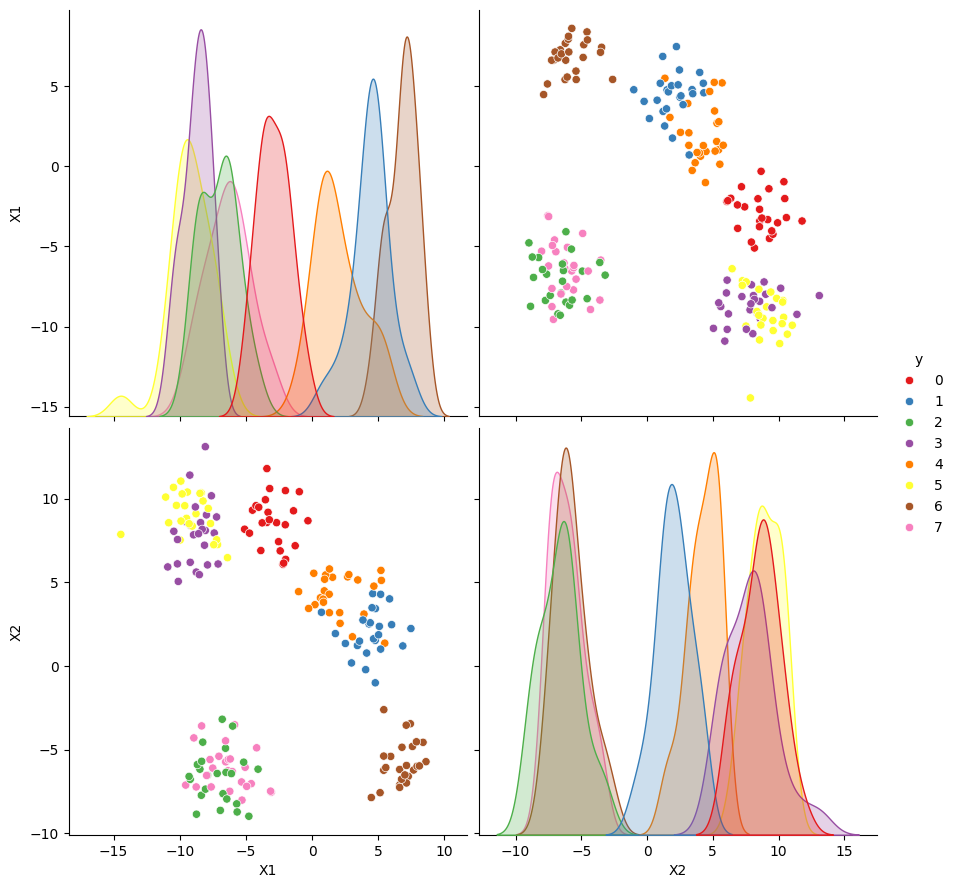

In [5]:
sns.pairplot(df, hue='y', palette="Set1", height=4.5)

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=RANDOM_STATE,
    test_size=0.25
)

In [7]:
from sklearn.neural_network import MLPClassifier

clf = MLPClassifier(
    hidden_layer_sizes=[10, 10],
    alpha=5,
    random_state=RANDOM_STATE,
    solver='lbfgs'
)

clf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


MLPClassifier(alpha=5, hidden_layer_sizes=[10, 10], random_state=42,
              solver='lbfgs')

In [8]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = y_test
y_pred = clf.predict(X_test)

print(confusion_matrix(y_true, y_pred))


[[10  0  0  0  0  0  0  0]
 [ 0  3  0  0  0  0  0  0]
 [ 0  0  5  0  0  0  0  1]
 [ 0  0  0  5  0  1  0  0]
 [ 0  0  0  0  5  0  0  0]
 [ 0  0  0  5  0  6  0  0]
 [ 0  0  0  0  0  0  6  0]
 [ 0  0  2  0  0  0  0  1]]


In [9]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         3
           2       0.71      0.83      0.77         6
           3       0.50      0.83      0.62         6
           4       1.00      1.00      1.00         5
           5       0.86      0.55      0.67        11
           6       1.00      1.00      1.00         6
           7       0.50      0.33      0.40         3

    accuracy                           0.82        50
   macro avg       0.82      0.82      0.81        50
weighted avg       0.84      0.82      0.82        50



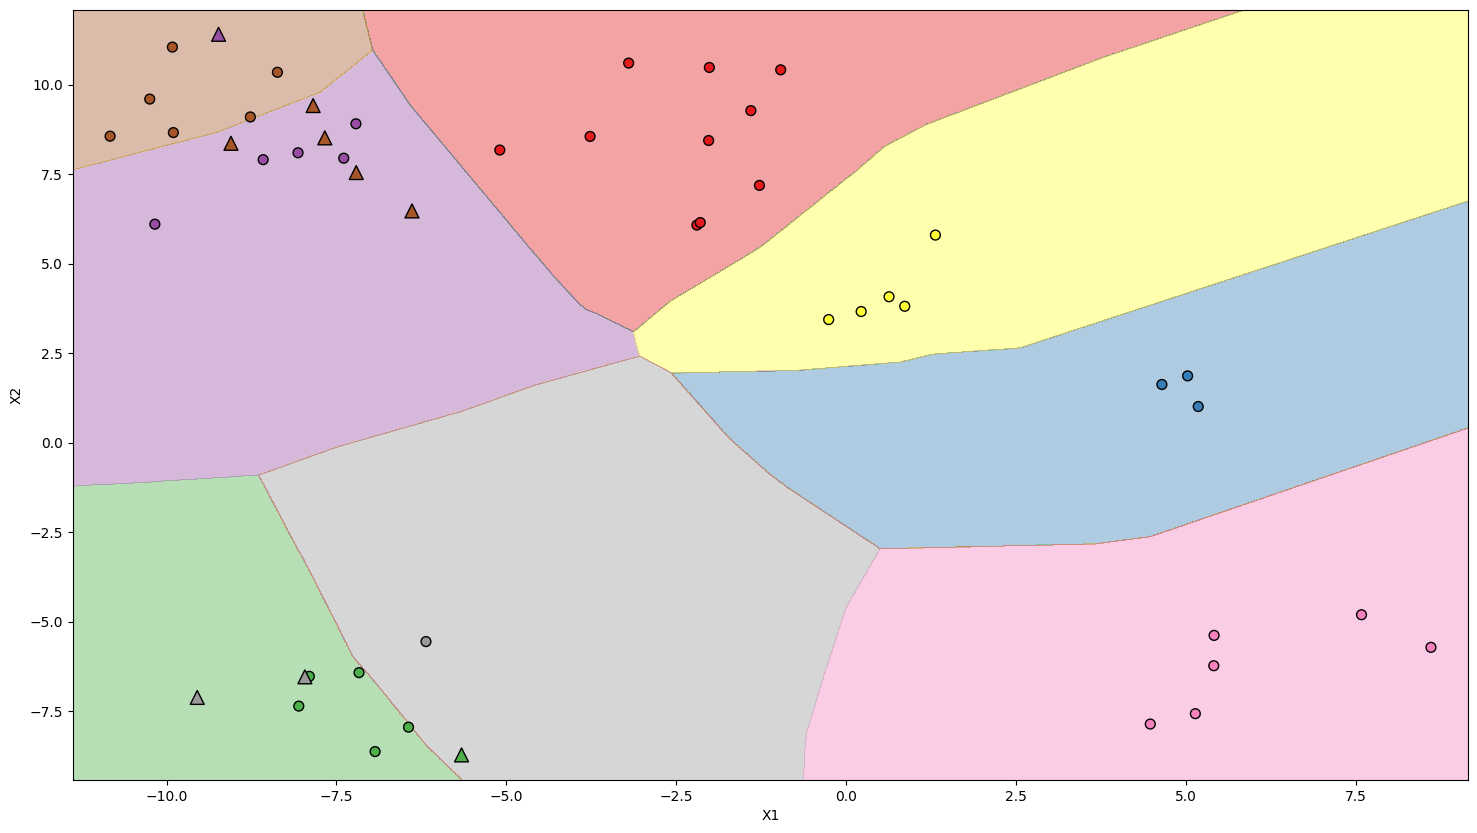

In [10]:
from matplotlib.colors import Normalize

def get_grid(data_x, data_y, padding_k=0.0, h=0.01):
    padding_x = data_x.std() * padding_k
    padding_y = data_y.std() * padding_k
    x_min, x_max = data_x.min() - padding_x, data_x.max() + padding_x
    y_min, y_max = data_y.min() - padding_y, data_y.max() + padding_y
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    return xx, yy

x_values = X_test[:, 0]
y_values = X_test[:, 1]

grid_x, grid_y = get_grid(x_values, y_values, padding_k=0.1)
grid = np.c_[grid_x.ravel(), grid_y.ravel()]
plt.figure(figsize=(18, 10))

plt.contourf(
    grid_x,
    grid_y,
    clf.predict(grid).reshape(grid_x.shape),
    cmap="Set1",
    alpha=0.4,
    levels=np.arange(-0.5, len(np.unique(y)) + 0.5, 1)
)
y_pred = clf.predict(X_test)
correct = y_test == y_pred
incorrect = ~correct

norm = Normalize(vmin=0, vmax=len(np.unique(y)) - 1)

plt.scatter(
    x_values[correct],
    y_values[correct],
    c=y_test[correct],
    cmap="Set1",
    marker="o",
    edgecolors="black",
    s=50,
    label="Правильно классифицированы",
    norm=norm,
)

plt.scatter(
    x_values[incorrect],
    y_values[incorrect],
    c=y_test[incorrect],
    cmap="Set1",
    marker="^",
    edgecolors="black",
    s=100,
    label="Неправильно классифицированы",
    norm=norm,
)

plt.xlabel("X1")
plt.ylabel("X2")

plt.show()
